# Prueba Intertrimestral

**Nombre:** Telmo 
**Apellidos:**  Plaza Bezos

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [1]:
import pandas as pd
import numpy as np
import sklearn.datasets

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error,
    classification_report,
    confusion_matrix
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier, LogisticRegression

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [2]:
def rental_fee(duration_min, bike_type, is_member):
    if bike_type not in ["classic", "electric"]:
        raise ValueError("El tipo de bicicleta debe ser 'classic' o 'electric'.")
    
    base_fee = 1.00 if bike_type == "classic" else 1.50
    cost_per_min = 0.05 if bike_type == "classic" else 0.08
    
    total = base_fee + (cost_per_min * duration_min)
    
    # descuento  miembro
    if is_member:
        total *= 0.80
        
    return round(total, 2)

In [3]:
rental_fee(20, "classic", False)

2.0

b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [4]:
def demand_label(total_rentals, threshold):
    if total_rentals >= threshold:
        return "Alta"
    elif total_rentals > (threshold / 2): 
        return "Media"
    else:
        return "Baja"

c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [5]:
data = {
    "duration_min": [10, 25, 5, 40, 15, 60, 8, 20, 35, 12],
    "bike_type": ["classic", "electric", "classic", "electric", "classic", 
                  "electric", "classic", "classic", "electric", "classic"],
    "is_member": [True, False, True, True, False, False, True, False, True, False],
    "total_rentals": [50, 15, 80, 20, 35, 5, 100, 45, 10, 60]
}

tripsDemo = pd.DataFrame(data)

In [6]:
tripsDemo["fee"] = tripsDemo.apply(lambda row: rental_fee(row["duration_min"], row["bike_type"], row["is_member"]), axis=1)

tripsDemo["demand"] = tripsDemo["total_rentals"].apply(lambda x: demand_label(x, 50))

display(tripsDemo)

,duration_min,bike_type,is_member,total_rentals,fee,demand
0,10,classic,True,50,1.20,Alta
1,25,electric,False,15,3.50,Baja
2,5,classic,True,80,1.00,Alta
3,40,electric,True,20,3.76,Baja
4,15,classic,False,35,1.75,Media
5,60,electric,False,5,6.30,Baja
6,8,classic,True,100,1.12,Alta
7,20,classic,False,45,2.00,Media
8,35,electric,True,10,3.44,Baja
9,12,classic,False,60,1.60,Alta


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [7]:
class MicromobilityTools:
    
    def calculate_fees(self, durations, bike_types, members):
        resultados = []
        for i in range(len(durations)):
            
            d = durations[i]
            b = bike_types[i]
            m = members[i]
            
            tarifa = rental_fee(d, b, m)
            resultados.append(tarifa)
            
        return resultados
    
    def label_demands(self, rentals_list, threshold):
        resultados = []
        for r in rentals_list:
            etiqueta = demand_label(r, threshold)
            resultados.append(etiqueta)
            
        return resultados

In [8]:
herramientas = MicromobilityTools()

lista_duraciones = [10, 20, 30]
lista_tipos = ["classic", "electric", "classic"]
lista_miembros = [True, False, False]

tarifas = herramientas.calculate_fees(lista_duraciones, lista_tipos, lista_miembros)
print("Tarifas calculadas:", tarifas)

lista_alquileres = [15, 20, 50, 80]
umbral = 40

etiquetas = herramientas.label_demands(lista_alquileres, umbral)
print(etiquetas)

Tarifas calculadas: [1.2, 3.1, 2.5]
['Baja', 'Baja', 'Alta', 'Alta']


## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [11]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv")


print("Filas y columnas:", mobilityData.shape)


print(mobilityData.head())

Filas y columnas: (17520, 23)
              datetime  year  month  day  hour  weekday  season  is_holiday  \
0  2025-01-01 00:00:00  2025      1    1     0        2  Winter           1   
1  2025-01-01 01:00:00  2025      1    1     1        2  Winter           1   
2  2025-01-01 02:00:00  2025      1    1     2        2  Winter           1   
3  2025-01-01 03:00:00  2025      1    1     3        2  Winter           1   
4  2025-01-01 04:00:00  2025      1    1     4        2  Winter           1   

   is_weekend  is_workingday  ... wind_kmh  precip_mm  casual_users  \
0           0              0  ...      9.7        0.0             2   
1           0              0  ...      2.8        0.0             1   
2           0              0  ...      9.0        0.0             1   
3           0              0  ...      5.4        0.0             2   
4           0              0  ...      2.4        0.0             1   

   member_users  total_rentals  avg_trip_min  avg_distance_km  elect

b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [12]:
def describeData(df):
    resumen = pd.DataFrame({
        "Tipo": df.dtypes,
        "Nulo": df.isnull().sum(),
        "% Nulos": (df.isnull().sum() / len(df)) * 100
    })
    return resumen

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [13]:
describeData(mobilityData)

,Tipo,Nulo,% Nulos
datetime,object,0,0.000000
year,int64,0,0.000000
month,int64,0,0.000000
day,int64,0,0.000000
hour,int64,0,0.000000
weekday,int64,0,0.000000
season,object,0,0.000000
is_holiday,int64,0,0.000000
is_weekend,int64,0,0.000000
is_workingday,int64,0,0.000000


Las variables que presentan valores faltantes son `avg_trip_min`, `humidity`, `electric_share` y `wind_kmh`. Como hicimos en los ejercicios de clase, antes de modelar se podría hacer una función que detectara y separara las filas válidas de las que tienen nulos creando una capa previa al modelización de validación, filtrando así los datos para quedarnos solo con el DataFrame limpio que es lo que nos interesa

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


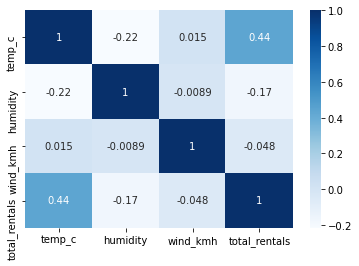

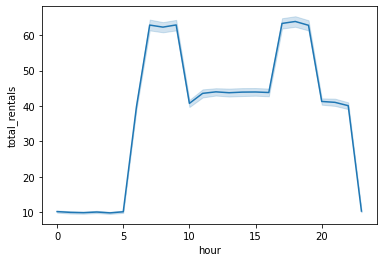

In [14]:
import matplotlib.pyplot as plt
import seaborn as sns

columnas = ['temp_c', 'humidity', 'wind_kmh', 'total_rentals']
sns.heatmap(mobilityData[columnas].corr(), annot=True, cmap="Blues")
plt.show()

sns.lineplot(data=mobilityData, x="hour", y="total_rentals")
plt.show()


1.Patrón horario (Gráfico de líneas):Existen dos picos de demanda muy marcados durante el día, uno por la mañana(rollo 8:00) y otro por la tarde (sobre las 17:00-18:00). Esto sugiere que la mayoría de los usuarios utilizan el servicio para desplazamientos rutinarios como ir y volver al trabajo.
2. Efecto del clima (Mapa de correlación):La variable `total_rentals` tiene una correlación positiva de 0.44 con la temperatura (`temp_c`), indicando que los alquileres suben cuando hace más calor.
3. Por el contrario, tiene una correlación negativa de -0.17 con la humedad (`humidity`), lo que significa que a mayor humedad, la demanda baja ligeramente ya que estara lloviendo.

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [15]:
targetVar = "total_rentals"
predictoras = ["hour", "temp_c", "humidity", "wind_kmh", "is_workingday"]

df_modelo = mobilityData[predictoras + [targetVar]].copy()

print("Nulos")
print(df_modelo.isna().sum())

# eliminar las filas que tengan algún nulo - simple
df_modelo = df_modelo.dropna()

X = df_modelo[predictoras]
y = df_modelo[targetVar]

Nulos
hour               0
temp_c             0
humidity         224
wind_kmh         142
is_workingday      0
total_rentals      0
dtype: int64


b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

print(f" Datos entrenamiento: {X_train.shape[0]} filas")
print(f"Datos  prueba: {X_test.shape[0]} filas")

 Datos entrenamiento: 12011 filas
Datos  prueba: 5148 filas


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [19]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print(f" R2: {r2_score(y_test, y_pred_lr):.4f}")
print(f"MSE: {mean_squared_error(y_test, y_pred_lr):.2f}")

 R2: 0.2818
MSE: 424.16


El modelo obtiene un R2 muy bajo y un error MSE alto, lo que significa que solo es capaz de explicar el 28% de la demanda. Esto demuestra que una regresión lineal (que traza una línea recta) es demasiado simple y no logra capturar bien los picos bruscos de alquileres a lo largo del día

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [20]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print(f" R2: {r2_score(y_test, y_pred_rf):.4f}")
print(f" MSE: {mean_squared_error(y_test, y_pred_rf):.2f}")

 R2: 0.8399
 MSE: 94.53


El modelo Random Forest funciona mucho mejor, logrando un R2 mucho mayor y reduciendo el MSE. Esto se debe a que los algoritmos basados en árboles de decisión son para modelar relaciones no lineales e interacciones complejas datos

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [21]:
print(mobilityData['high_demand'].value_counts(normalize=True))

0    0.688984
1    0.311016
Name: high_demand, dtype: float64


b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [22]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

predictoras = ["hour", "temp_c", "humidity", "wind_kmh", "is_workingday"]

df_clf = mobilityData.dropna(subset=predictoras + ['high_demand']).copy()

X_clf = df_clf[predictoras]
y_clf = df_clf['high_demand']

X_train_clf, X_test_clf, y_train_clf, y_test_clf = train_test_split(X_clf, y_clf, test_size=0.30, random_state=42)

clf_log = LogisticRegression(max_iter=1000, random_state=42)

clf_log.fit(X_train_clf, y_train_clf)

LogisticRegression(max_iter=1000, random_state=42)

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


In [23]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import seaborn as sns
import matplotlib.pyplot as plt

predictions = clf_log.predict(X_test_clf)

print("Classification report")
print(classification_report(y_test_clf, predictions))

print(f"\nAccuracy: {accuracy_score(y_test_clf, predictions):.4f}")

cm = confusion_matrix(y_test_clf, predictions)
print(cm)

Classification report
              precision    recall  f1-score   support

           0       0.76      0.91      0.83      3532
           1       0.67      0.38      0.48      1616

    accuracy                           0.75      5148
   macro avg       0.72      0.65      0.66      5148
weighted avg       0.73      0.75      0.72      5148


Accuracy: 0.7457
[[3230  302]
 [1007  609]]


d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


La alta demanda está impulsada principalmente por las horas punta en días laborables y por el aumento de la temperatura, tal como vimos en la exploración de datos.
El clima adverso (alta humedad y viento) frena la demanda, aunque viendo la matriz de confusión, al modelo logístico le cuesta detectar con exactitud todos los casos reales de alta demanda (recall)

## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



Se ha comprobado que la demanda de micromovilidad está impulsada por las horas punta en días laborables (8:00 y 18:00) y las buenas temperaturas, mientras que la lluvia y el viento la reducen drásticamente.

El modelo Random Forest funcionó mejor que la Regresión Lineal porque es capaz de capturar estos patrones no lineales y las interacciones complejas entre la hora y el tipo de día.

Con más datos y tiempo, mejoraría el modelo añadiendo variables espaciales como ubicacion para concluir el tema del clima, el impacto de eventos locales y un sistema de precios dinámicos para optimizar ingresos